1. How do the number of crashes vary by hour, month and year in each borough?
   Measure: crash counts grouped by hour of day, month and year, split by borough.

2. Which borough has the highest average number of injuries per crash?
   Measure: total persons injured / total crashes, per borough. The borough with the
   highest average ranks first.

3. Which contributing factors are most common overall, and which are
   over-represented in crashes with injuries?
   Measure: each factor's share of all crashes vs its share of crashes with at least one
   injury, compared by rank.

4. How do injuries and deaths differ among pedestrians, cyclists, motorists and others?
   Measure: injured and killed counts per group (pedestrians, cyclists, motorists, other), with killed per injured as a severity
   rate, broken down by borough, hour and contributing factor.

5. Which vehicle types appear most often in crashes in each borough?
   Measure: for each borough, rank vehicle types by the number of crashes involving them.

6. How has the average number of injuries per crash changed from year to year?
   Measure: injuries per crash for each full year, and the year-over-year percentage change
   = (this year - last year) / last year * 100.

## Q1. How do crashes vary by hour, month and year in each borough?

**What I measured:** number of reported crashes by year, month and hour of day, split by borough.
**Years I used:** 2022 to 2025 only. 2026 is not a full year (the data stops on Nov 9), so it would look like crashes dropped when they didn't.
**Cleaning that matters here:** crashes with no borough are labeled `Unknown`, and crashes logged at exactly 00:00 are left out of the hourly part only.

Each section below has a table, a chart, what I found, and a warning about how far to trust it.

In [1]:
import calendar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path

Path("images").mkdir(exist_ok=True)

df = pd.read_csv(
    "data/clean/collisions_clean.csv",
    dtype={"ZIP CODE": "string"},
    parse_dates=["CRASH INFO"],
    low_memory=False,
)

# Chart style: validated categorical colours, light grid, no top/right borders
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
GRAY, INK, INK2, GRID = "#8a8984", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False,
})

NAMED = ["BRONX", "BROOKLYN", "MANHATTAN", "QUEENS", "STATEN ISLAND"]
COLOR = {"BRONX": BLUE, "BROOKLYN": ORANGE, "MANHATTAN": AQUA, "QUEENS": YELLOW, "STATEN ISLAND": MAGENTA, "Unknown": GRAY}
label = lambda b: b if b == "Unknown" else b.title()
thousands = FuncFormatter(lambda x, _: f"{x:,.0f}")
SOURCE = "Source: NYC Open Data, Motor Vehicle Collisions - Crashes."

def headline(fig, title, subtitle):
    """Finding as the title, plain description of what is plotted underneath."""
    fig.suptitle(title, x=0.01, y=1.09, ha="left", fontsize=13, fontweight="bold")
    fig.text(0.01, 1.01, subtitle, ha="left", fontsize=10, color=INK2)

def footer(fig, note):
    fig.text(0.01, -0.07, SOURCE + " " + note, ha="left", fontsize=8, color=INK2)

def save(fig, name):
    fig.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")

# Scope: full years only (2026 stops on Nov 9, a partial year would look like a drop)
full = df[df["CRASH YEAR"].between(2022, 2025)].copy()
print(f"Crashes analysed: {len(full):,} of {len(df):,} (2022-2025)")

Crashes analysed: 377,371 of 449,586 (2022-2025)


## A. By year

In [2]:
by_year = full.groupby(["CRASH YEAR", "BOROUGH"]).size().unstack()[NAMED + ["Unknown"]]
by_year["TOTAL"] = by_year.sum(axis=1)

assert by_year["TOTAL"].sum() == len(full)          # check: no crash lost
by_year["NAMED BOROUGHS"] = by_year[NAMED].sum(axis=1)   # the five boroughs together, without Unknown
display(by_year)
print("Year-over-year change (%):")
display((by_year.pct_change() * 100).round(1))
print("Change 2022 -> 2025 (%):")
display(((by_year.loc[2025] / by_year.loc[2022] - 1) * 100).round(1).to_frame("change_%").T)
print("Change 2024 -> 2025 (number of crashes):")
display((by_year.loc[2025] - by_year.loc[2024]).to_frame("change").T)

BOROUGH,BRONX,BROOKLYN,MANHATTAN,QUEENS,STATEN ISLAND,Unknown,TOTAL,NAMED BOROUGHS
CRASH YEAR,,,,,,,,
2022,12287,23370,11992,18429,2718,35092,103888,68796
2023,10510,22892,11826,17788,2724,30868,96608,65740
2024,10039,22792,11911,17820,2698,26056,91316,65260
2025,12291,26712,14488,21840,3128,7100,85559,78459


Year-over-year change (%):


BOROUGH,BRONX,BROOKLYN,MANHATTAN,QUEENS,STATEN ISLAND,Unknown,TOTAL,NAMED BOROUGHS
CRASH YEAR,,,,,,,,
2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023,-14.5,-2.0,-1.4,-3.5,0.2,-12.0,-7.0,-4.4
2024,-4.5,-0.4,0.7,0.2,-1.0,-15.6,-5.5,-0.7
2025,22.4,17.2,21.6,22.6,15.9,-72.8,-6.3,20.2


Change 2022 -> 2025 (%):


BOROUGH,BRONX,BROOKLYN,MANHATTAN,QUEENS,STATEN ISLAND,Unknown,TOTAL,NAMED BOROUGHS
change_%,0.0,14.3,20.8,18.5,15.1,-79.8,-17.6,14.0


Change 2024 -> 2025 (number of crashes):


BOROUGH,BRONX,BROOKLYN,MANHATTAN,QUEENS,STATEN ISLAND,Unknown,TOTAL,NAMED BOROUGHS
change,2252,3920,2577,4020,430,-18956,-5757,13199


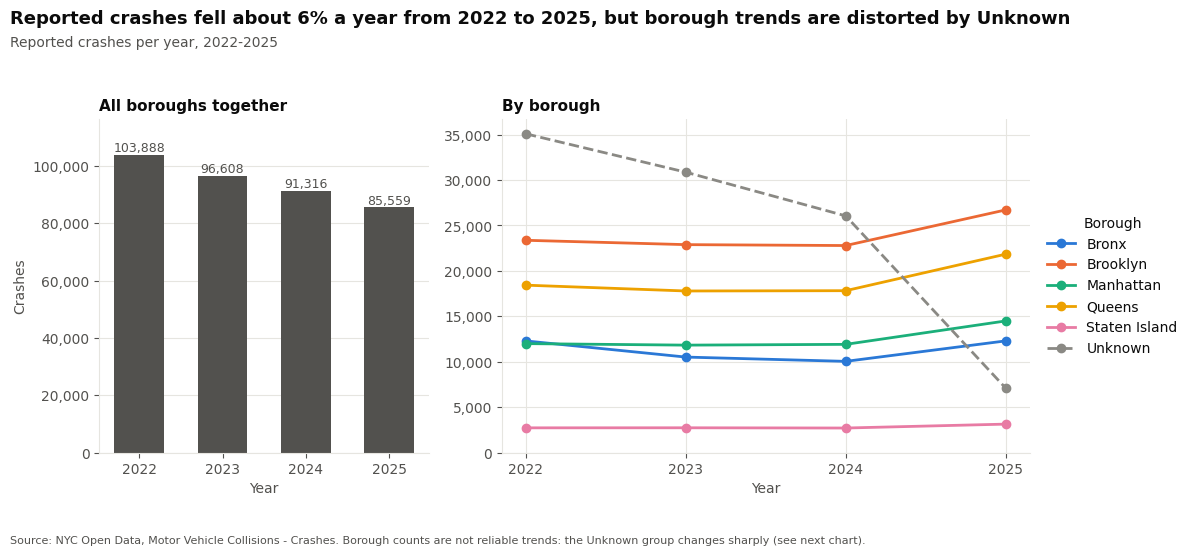

In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.6]})

# Left: the total (not affected by how boroughs were labelled)
bars = a1.bar(by_year.index.astype(str), by_year["TOTAL"], color=INK2, width=0.6)
for b, v in zip(bars, by_year["TOTAL"]):
    a1.text(b.get_x() + b.get_width() / 2, v + 1200, f"{v:,.0f}", ha="center", fontsize=9, color=INK2)
a1.set_title("All boroughs together")
a1.set_ylabel("Crashes"); a1.set_xlabel("Year")
a1.set_ylim(0, by_year["TOTAL"].max() * 1.12); a1.yaxis.set_major_formatter(thousands)
a1.grid(axis="x", visible=False)

# Right: by borough
for col in NAMED + ["Unknown"]:
    a2.plot(by_year.index, by_year[col], marker="o", markersize=6, linewidth=2,
            color=COLOR[col], linestyle="--" if col == "Unknown" else "-", label=label(col))
a2.set_title("By borough")
a2.set_xlabel("Year"); a2.set_xticks(by_year.index); a2.yaxis.set_major_formatter(thousands)
a2.set_ylim(0, None)
a2.legend(title="Borough", loc="center left", bbox_to_anchor=(1.01, 0.5))

headline(fig, 'Reported crashes fell about 6% a year from 2022 to 2025, but borough trends are distorted by Unknown', "Reported crashes per year, 2022-2025")
footer(fig, "Borough counts are not reliable trends: the Unknown group changes sharply (see next chart).")
fig.tight_layout()
save(fig, "q1_year")
plt.show()

### What I found: year
- Total crashes went down every year: 103,888, then 96,608, then 91,316, then 85,559. That is about 6% less each year and **17.6% less** from 2022 to 2025.
- In 2025 every named borough went up (from +15.9% in Staten Island to +22.6% in Queens), but `Unknown` dropped 72.8%.
- The five named boroughs together gained 13,199 crashes in 2025 while Unknown lost 18,956.

**Warning:** that 2025 increase is not real growth in crashes. It comes from how boroughs were recorded (see the next chart). I only trust the total line to compare years, not the borough lines.

### Why I don't trust the borough trends: the Unknown group

Share of crashes with Unknown borough, by year (%):


CRASH YEAR,2022,2023,2024,2025,2026
unknown_share_%,33.8,32.0,28.5,8.3,3.1


Monthly share (%) around the drop:


CRASH INFO,2024-08-01,2024-09-01,2024-10-01,2024-11-01,2024-12-01,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01
unknown_share_%,30.3,30.0,26.8,18.4,19.5,20.5,20.7,21.7,14.1,3.4,3.1,3.2


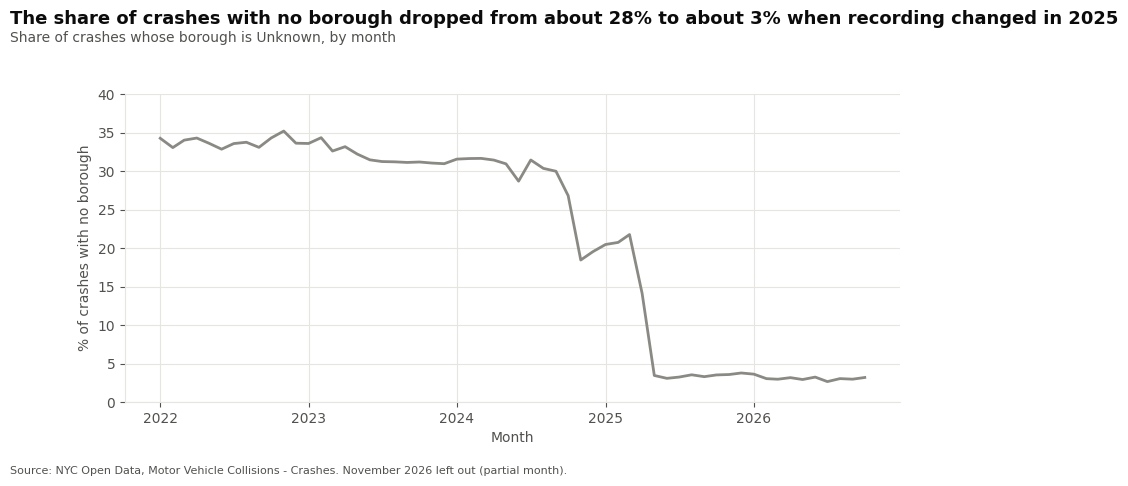

In [4]:
month_start = df["CRASH INFO"].dt.to_period("M").dt.to_timestamp()
complete = df["CRASH INFO"] < "2026-11-01"            # Nov 2026 is partial
unknown_share = df["BOROUGH"].eq("Unknown")[complete].groupby(month_start[complete]).mean() * 100

unknown_by_year = df["BOROUGH"].eq("Unknown")[complete].groupby(df["CRASH YEAR"][complete]).mean() * 100
print("Share of crashes with Unknown borough, by year (%):")
display(unknown_by_year.round(1).to_frame("unknown_share_%").T)
print("Monthly share (%) around the drop:")
display(unknown_share["2024-08-01":"2025-07-01"].round(1).to_frame("unknown_share_%").T)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(unknown_share.index, unknown_share.values, color=GRAY, linewidth=2)
ax.set_ylabel("% of crashes with no borough"); ax.set_xlabel("Month")
ax.set_ylim(0, 40)
headline(fig, 'The share of crashes with no borough dropped from about 28% to about 3% when recording changed in 2025', "Share of crashes whose borough is Unknown, by month")
footer(fig, "November 2026 left out (partial month).")
save(fig, "q1_unknown_share")
plt.show()

### What I found: Unknown borough
- Share of crashes with no borough: 33.8% in 2022, 32.0% in 2023, 28.5% in 2024, 8.3% in 2025 and 3.1% in 2026.
- The big drop happens between April 2025 (14.1%) and May 2025 (3.4%). A change that sudden is a change in how the data is recorded, not in traffic.

**What this means for the rest:** comparing boroughs year by year mixes real changes with boroughs that just got filled in. So for months and hours I compare the shape (shares and an index), not raw counts.

## B. By month

In [5]:
# Months have different lengths, so compare crashes PER DAY, then index to the average month (100)
days_in_month = pd.Series({m: sum(calendar.monthrange(y, m)[1] for y in range(2022, 2026)) for m in range(1, 13)})

by_month = full.groupby(["CRASH MONTH", "BOROUGH"]).size().unstack()[NAMED + ["Unknown"]]
by_month["TOTAL"] = by_month.sum(axis=1)
assert by_month["TOTAL"].sum() == len(full)

per_day = by_month.div(days_in_month, axis=0)
month_index = per_day / per_day.mean() * 100

print("Crashes per month, 2022-2025 combined:")
display(by_month)
print("Index (100 = the average month, adjusted for number of days):")
display(month_index.round(1))

Crashes per month, 2022-2025 combined:


BOROUGH,BRONX,BROOKLYN,MANHATTAN,QUEENS,STATEN ISLAND,Unknown,TOTAL
CRASH MONTH,,,,,,,
1,3457,7177,3359,5621,867,8922,29403
2,3112,6598,3228,5188,769,8209,27104
3,3746,7768,3955,5912,859,9696,31936
4,3624,7474,3962,5766,846,8735,30407
5,4114,8694,4725,6880,1004,8874,34291
6,4018,8531,4611,6705,1054,8203,33122
7,3981,8239,4178,6551,938,8152,32039
8,3847,8011,4294,6406,937,8075,31570
9,3788,8584,4553,6574,942,8116,32557


Index (100 = the average month, adjusted for number of days):


BOROUGH,BRONX,BROOKLYN,MANHATTAN,QUEENS,STATEN ISLAND,Unknown,TOTAL
CRASH MONTH,,,,,,,
1,90.3,88.3,78.9,87.3,90.7,106.0,91.8
2,89.2,89.1,83.2,88.4,88.3,107.0,92.9
3,97.9,95.6,92.9,91.9,89.9,115.2,99.7
4,97.8,95.1,96.1,92.6,91.5,107.3,98.1
5,107.5,107.0,110.9,106.9,105.0,105.5,107.1
6,108.5,108.5,111.9,107.6,113.9,100.7,106.9
7,104.0,101.4,98.1,101.8,98.1,96.9,100.1
8,100.5,98.6,100.8,99.5,98.0,96.0,98.6
9,102.3,109.2,110.5,105.5,101.8,99.7,105.1


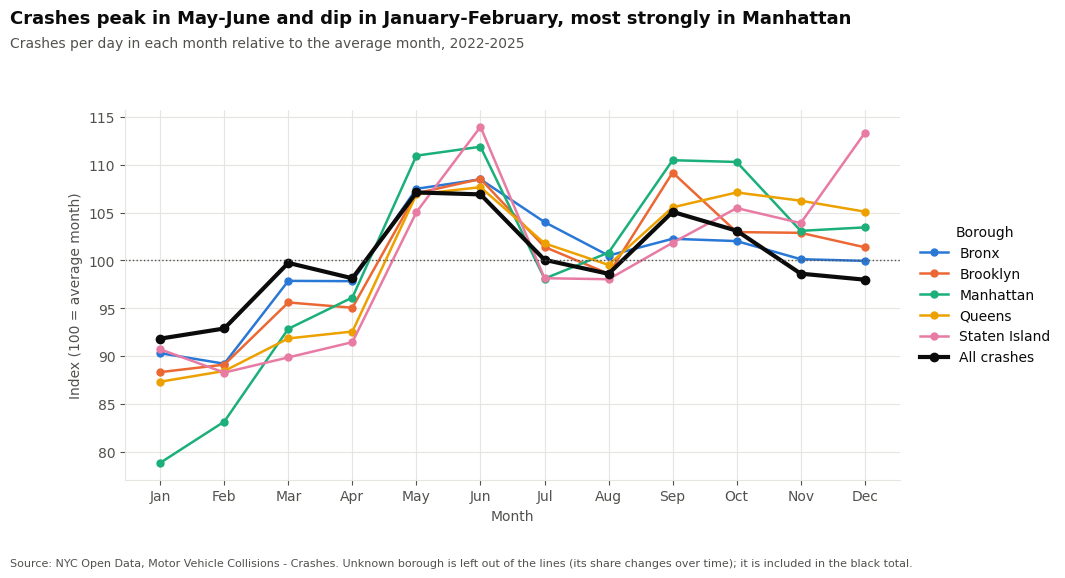

In [6]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(10, 4.8))
for col in NAMED:
    ax.plot(range(1, 13), month_index[col], marker="o", markersize=5, linewidth=1.8, color=COLOR[col], label=label(col))
ax.plot(range(1, 13), month_index["TOTAL"], marker="o", markersize=6, linewidth=3, color=INK, label="All crashes")
ax.axhline(100, color=INK2, linestyle=":", linewidth=1)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(months)
ax.set_ylabel("Index (100 = average month)"); ax.set_xlabel("Month")
ax.legend(title="Borough", loc="center left", bbox_to_anchor=(1.01, 0.5))
headline(fig, 'Crashes peak in May-June and dip in January-February, most strongly in Manhattan', "Crashes per day in each month relative to the average month, 2022-2025")
footer(fig, "Unknown borough is left out of the lines (its share changes over time); it is included in the black total.")
save(fig, "q1_month")
plt.show()

### What I found: month
Months have different numbers of days, so I counted crashes per day and set the average month to 100.
- The highest months are May (107.1) and June (106.9). The lowest are January (91.8) and February (92.9).
- Manhattan changes the most through the year (from 78.9 to 111.9). The other boroughs stay closer to the overall line.

**Warning:** the difference between seasons is only about 8% up or down, which is small compared to the changes caused by the Unknown problem.

## C. By hour of day

In [7]:
# Data check before the hourly analysis: how many crashes are logged at exactly 00:00?
h0 = full[full["CRASH HOUR"] == 0]
at_midnight = full["CRASH TIME"] == "00:00"
print("Crashes in hour 0:", len(h0))
print("  logged at exactly 00:00:", int((h0["CRASH TIME"] == "00:00").sum()))
print("  average per minute for 00:01-00:59:", round((h0["CRASH TIME"] != "00:00").sum() / 59))
print("  most common times:", h0["CRASH TIME"].value_counts().head(4).to_dict())

Crashes in hour 0: 17027
  logged at exactly 00:00: 6613
  average per minute for 00:01-00:59: 177
  most common times: {'00:00': 6613, '00:30': 1021, '00:15': 589, '00:20': 564}


In [8]:
# Decision: 00:00 looks like a default for "time not recorded", so leave those crashes out of the HOURLY analysis only
hourly = full[~at_midnight]
print(f"Excluded from the hourly analysis: {int(at_midnight.sum()):,} crashes ({at_midnight.mean() * 100:.1f}% of 2022-2025)")

by_hour = hourly.groupby(["CRASH HOUR", "BOROUGH"]).size().unstack()[NAMED + ["Unknown"]]
by_hour["TOTAL"] = by_hour.sum(axis=1)
assert by_hour["TOTAL"].sum() == len(hourly)

# Share of each borough's crashes that happen in each hour (so boroughs of different size are comparable)
hour_share = by_hour / by_hour.sum() * 100
print("Crashes per hour:")
display(by_hour)
print("Share of crashes in each hour (%):")
display(hour_share.round(1))
print("Peak hour per column:", hour_share.idxmax().to_dict())
print("Quietest hour per column:", hour_share.idxmin().to_dict())
print("Share of all crashes between 3 pm and 6:59 pm:", round(hour_share.loc[15:18, "TOTAL"].sum(), 1), "%")

# Reported times are often rounded: how many sit exactly on the hour?
minute = hourly["CRASH TIME"].str[3:].astype(int)
print(f"Crashes logged on the hour (minute :00): {(minute == 0).mean() * 100:.1f}% (about {100 / 60:.1f}% if times were spread evenly)")

Excluded from the hourly analysis: 6,613 crashes (1.8% of 2022-2025)
Crashes per hour:


BOROUGH,BRONX,BROOKLYN,MANHATTAN,QUEENS,STATEN ISLAND,Unknown,TOTAL
CRASH HOUR,,,,,,,
0,1085,2351,1384,2031,270,3293,10414
1,1015,2047,1191,1817,192,2762,9024
2,828,1671,909,1588,201,2181,7378
3,755,1470,879,1565,187,2007,6863
4,904,1612,861,1818,154,2399,7748
5,874,1703,798,1797,187,2467,7826
6,1214,2419,1139,2192,275,3258,10497
7,1872,3434,1546,2856,451,3986,14145
8,2536,5105,2311,4237,627,5196,20012


Share of crashes in each hour (%):


BOROUGH,BRONX,BROOKLYN,MANHATTAN,QUEENS,STATEN ISLAND,Unknown,TOTAL
CRASH HOUR,,,,,,,
0,2.5,2.5,2.8,2.7,2.4,3.4,2.8
1,2.3,2.2,2.4,2.4,1.7,2.8,2.4
2,1.9,1.8,1.8,2.1,1.8,2.2,2.0
3,1.7,1.6,1.8,2.1,1.7,2.1,1.9
4,2.0,1.7,1.7,2.4,1.4,2.5,2.1
5,2.0,1.8,1.6,2.4,1.7,2.5,2.1
6,2.7,2.6,2.3,2.9,2.5,3.3,2.8
7,4.2,3.7,3.1,3.8,4.0,4.1,3.8
8,5.7,5.4,4.7,5.7,5.6,5.3,5.4


Peak hour per column: {'BRONX': 17, 'BROOKLYN': 17, 'MANHATTAN': 16, 'QUEENS': 17, 'STATEN ISLAND': 15, 'Unknown': 17, 'TOTAL': 17}
Quietest hour per column: {'BRONX': 3, 'BROOKLYN': 3, 'MANHATTAN': 5, 'QUEENS': 3, 'STATEN ISLAND': 4, 'Unknown': 3, 'TOTAL': 3}
Share of all crashes between 3 pm and 6:59 pm: 24.4 %


Crashes logged on the hour (minute :00): 14.9% (about 1.7% if times were spread evenly)


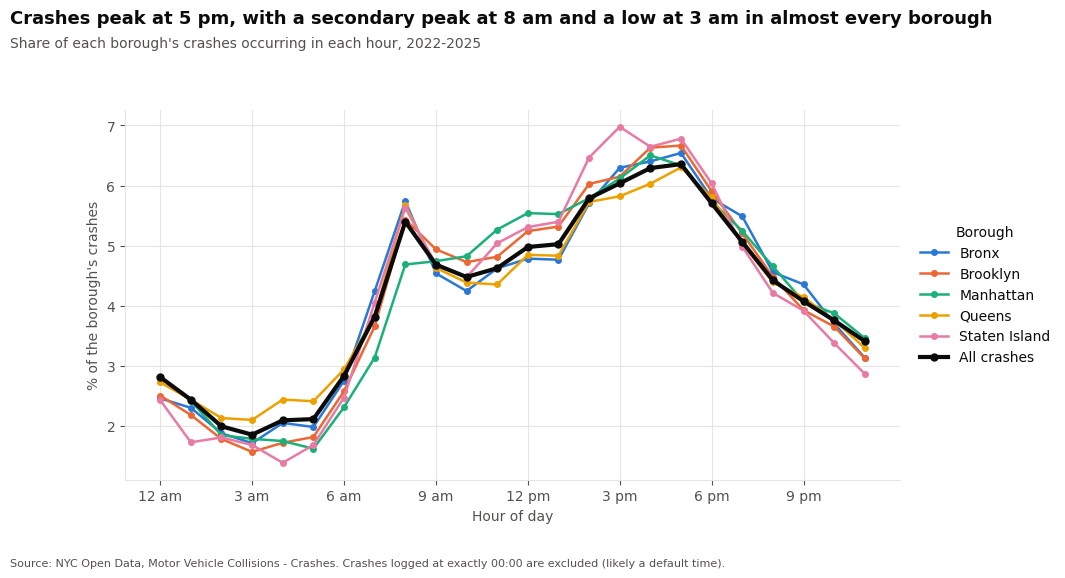

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for col in NAMED:
    ax.plot(hour_share.index, hour_share[col], marker="o", markersize=4, linewidth=1.8, color=COLOR[col], label=label(col))
ax.plot(hour_share.index, hour_share["TOTAL"], marker="o", markersize=5, linewidth=3, color=INK, label="All crashes")
ax.set_xticks(range(0, 24, 3)); ax.set_xticklabels(["12 am", "3 am", "6 am", "9 am", "12 pm", "3 pm", "6 pm", "9 pm"])
ax.set_xlabel("Hour of day"); ax.set_ylabel("% of the borough's crashes")
ax.legend(title="Borough", loc="center left", bbox_to_anchor=(1.01, 0.5))
headline(fig, 'Crashes peak at 5 pm, with a secondary peak at 8 am and a low at 3 am in almost every borough', "Share of each borough's crashes occurring in each hour, 2022-2025")
footer(fig, "Crashes logged at exactly 00:00 are excluded (likely a default time).")
save(fig, "q1_hour")
plt.show()

### What I found: hour
- 6,613 crashes (1.8%) are logged at exactly 00:00. That looks like a default for "no time", so I left them out of this part.
- The busiest hour is 5 pm in the Bronx, Brooklyn, Queens and Unknown (4 pm in Manhattan, 3 pm in Staten Island). Between 3 pm and 6:59 pm happens **24.4%** of all crashes.
- There is a smaller peak at 8 am (5.4%). The quietest hour is 3 am (5 am in Manhattan, 4 am in Staten Island).
- 14.9% of the times are exactly on the hour, when it should be around 1.7% if times were random. So people round the time and the hourly result is approximate.

**Warning:** I used shares (each borough adds up to 100%) so big and small boroughs can be compared by shape and not by size.

## Answer to Q1
Crashes follow the same pattern in every borough: they peak around 5 pm with a smaller peak at 8 am, they are lowest around 3 am, and they are highest in May and June and lowest in January and February. From 2022 to 2025 total crashes dropped 17.6%, but I can't say that for each borough because the share of crashes with no borough went from about 28% in 2024 to about 3% from May 2025.

---
# Q2. Which borough has the highest average number of injuries per crash?

**What I measured:** total `NUMBER OF PERSONS INJURED` divided by the number of crashes, per borough. The highest average is first.
**Years I used:** 2022 to 2025 (full years).

**Decisions**
- Unknown borough: it is not ranked. I can't say where those crashes happened, so it can't "win". I show it separately as a reference.
- Denominator: every crash, including crashes with 0 injuries.

In [10]:
q2_df = df[df["CRASH YEAR"].between(2022, 2025)]
q2 = q2_df.groupby("BOROUGH").agg(
    crashes=("COLLISION_ID", "size"),
    injured=("NUMBER OF PERSONS INJURED", "sum"),
)
q2["avg_injured"] = q2["injured"] / q2["crashes"]
q2 = q2.sort_values("avg_injured", ascending=False)
q2

,crashes,injured,avg_injured
BOROUGH,,,
Unknown,99116,61829,0.623804
BRONX,45127,25431,0.563543
BROOKLYN,95766,52782,0.551156
QUEENS,75877,40494,0.533680
STATEN ISLAND,11268,5510,0.488995
MANHATTAN,50217,23811,0.474162


In [11]:
# check I didn't lose any rows
assert q2["crashes"].sum() == len(q2_df)
assert q2["injured"].sum() == q2_df["NUMBER OF PERSONS INJURED"].sum()

ranked = q2.drop(index="Unknown")   # unknown is not ranked, only the 5 boroughs
city_avg = ranked["injured"].sum() / ranked["crashes"].sum()
print(f"Average of the five named boroughs together: {city_avg:.3f}")
print(f"Unknown: {q2.loc['Unknown', 'avg_injured']:.3f} ({q2.loc['Unknown', 'crashes'] / q2['crashes'].sum() * 100:.1f}% of crashes)")
print(f"Gap between 1st and 2nd: {ranked['avg_injured'].iloc[0] - ranked['avg_injured'].iloc[1]:.3f} injuries per crash")
ranked.round(3)

Average of the five named boroughs together: 0.532
Unknown: 0.624 (26.3% of crashes)
Gap between 1st and 2nd: 0.012 injuries per crash


,crashes,injured,avg_injured
BOROUGH,,,
BRONX,45127,25431,0.564
BROOKLYN,95766,52782,0.551
QUEENS,75877,40494,0.534
STATEN ISLAND,11268,5510,0.489
MANHATTAN,50217,23811,0.474


In [12]:
# does the ranking stay the same every year?
by_year_avg = q2_df.groupby(["CRASH YEAR", "BOROUGH"])["NUMBER OF PERSONS INJURED"].mean().unstack().drop(columns="Unknown")
display(by_year_avg.round(3))
print("Highest borough each year:", by_year_avg.idxmax(axis=1).to_dict())

BOROUGH,BRONX,BROOKLYN,MANHATTAN,QUEENS,STATEN ISLAND
CRASH YEAR,,,,,
2022,0.474,0.493,0.428,0.462,0.451
2023,0.553,0.541,0.476,0.535,0.501
2024,0.600,0.577,0.485,0.558,0.483
2025,0.631,0.589,0.502,0.573,0.516


Highest borough each year: {2022: 'BROOKLYN', 2023: 'BRONX', 2024: 'BRONX', 2025: 'BRONX'}


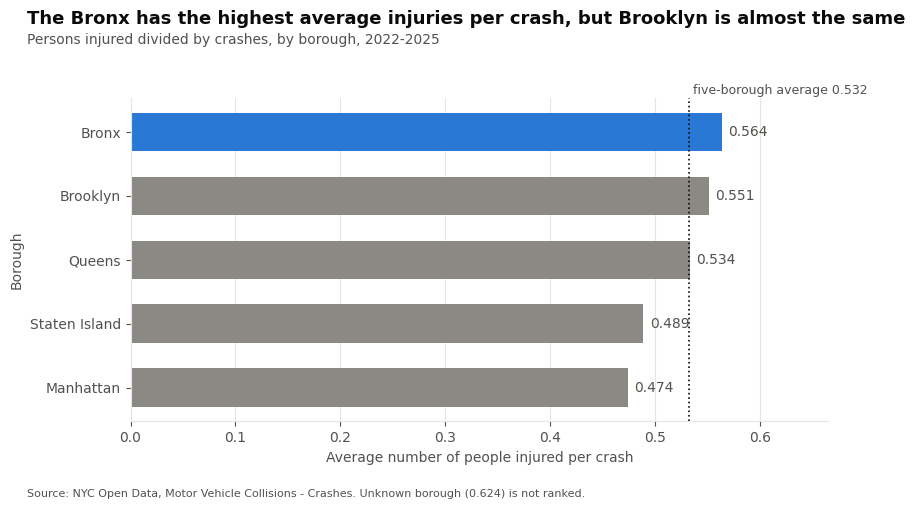

In [13]:
order = ranked.sort_index().sort_values("avg_injured").index        # sorted so the highest is on top
vals = ranked.loc[order, "avg_injured"]
colors = [BLUE if b == ranked.index[0] else GRAY for b in order]  # only the winner in blue

fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.barh([label(b) for b in order], vals, color=colors, height=0.6)
for b, v in zip(bars, vals):
    ax.text(v + 0.006, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center", fontsize=10, color=INK2)
ax.axvline(city_avg, color=INK, linestyle=":", linewidth=1.2)
ax.text(city_avg, len(order) - 0.45, f" five-borough average {city_avg:.3f}", fontsize=9, color=INK2, va="bottom")
ax.set_xlim(0, vals.max() * 1.18)
ax.set_xlabel("Average number of people injured per crash")
ax.set_ylabel("Borough")
ax.grid(axis="y", visible=False)
headline(fig, "The Bronx has the highest average injuries per crash, but Brooklyn is almost the same",
         "Persons injured divided by crashes, by borough, 2022-2025")
footer(fig, f"Unknown borough ({q2.loc['Unknown', 'avg_injured']:.3f}) is not ranked.")
save(fig, "q2_avg_injured")
plt.show()

### What I found: Q2
- The borough with the highest average of injuries per crash is the Bronx, with 0.564 injuries per crash, followed closely by Brooklyn with 0.551. The other boroughs are Queens (0.534), Staten Island (0.489) and Manhattan (0.474).
- The gap between the Bronx and Brooklyn is only 0.012, which is about 2% of Brooklyn's average.
- In 2022 Brooklyn was the highest (0.493 vs 0.474). From 2023 on the Bronx is first every year, and the gap is bigger in recent years (0.553 vs 0.541 in 2023, 0.631 vs 0.589 in 2025).
- Unknown is around 1/4 of the crashes (26.3%) and it has the highest average of all (0.624). I left it out of the ranking because I can't say which borough those crashes belong to.
- The averages went up in every borough from 2022 to 2025. I look at that change over time in Q6.

**Warning:** the top two boroughs are very close, and the Unknown crashes are not assigned to any borough, so I can't test how they would change the ranking. Also, an average hides how the injuries are spread: most crashes have 0 injuries, so a higher average can mean more crashes with injuries or more people hurt in each crash.

## Answer to Q2
Among the five named boroughs, the Bronx has the highest average of injuries per crash (0.564), but its lead over Brooklyn is only 0.012 and the Unknown crashes are not included in the ranking.

---
# Q3. Which contributing factors are most common overall, and which are over-represented in crashes with injuries?

**What I measured:** each factor's share of all crashes vs its share of the crashes with at least one injury (`INJURY CRASH == True`), compared by rank and by a ratio (share in injury crashes / share in all crashes).
**Years I used:** 2022 to 2025 (full years), same as Q1 and Q2.

**Decisions**
- "Unspecified" and "Does Not Apply": I show them separately and I don't rank them. Together they are in about 77% of the crashes, and they don't say anything about the cause.
- A crash that lists the same factor in 2 vehicles counts once for that factor.
- I only rank factors that appear in at least 500 crashes, because the ratio of a very small factor is just noise.
- "Illnes" is a typo in the data, I fixed it to "Illness".

In [14]:
# the factors are in 5 columns (one per vehicle), I need one row per crash and factor
q3_df = df[df["CRASH YEAR"].between(2022, 2025)]
factor_cols = [c for c in df.columns if c.startswith("CONTRIBUTING FACTOR VEHICLE")]

long = (
    q3_df[["COLLISION_ID", "INJURY CRASH"] + factor_cols]
    .melt(id_vars=["COLLISION_ID", "INJURY CRASH"], value_vars=factor_cols, value_name="FACTOR")
    .dropna(subset=["FACTOR"])      # a crash with 2 vehicles has nothing in columns 3 to 5
    .drop(columns="variable")
)
long["FACTOR"] = long["FACTOR"].replace({"Illnes": "Illness"})   # typo in the data
rows_before = len(long)
long = long.drop_duplicates(subset=["COLLISION_ID", "FACTOR"])    # same factor in 2 vehicles counts once
print(f"Rows before removing duplicates: {rows_before:,}")
print(f"Rows after (one per crash and factor): {len(long):,}")
long.head()

Rows before removing duplicates: 708,306
Rows after (one per crash and factor): 598,020


,COLLISION_ID,INJURY CRASH,FACTOR
0,89508879168d096a1f43a85a0b77704f,False,Does Not Apply
1,a72d8fec0ddcd2c75ea88f763d0e2327,True,Does Not Apply
2,8cd6d0905e14d6296c857bdcaed9c84b,False,Reaction to Uninvolved Vehicle
3,cda7e3e264d48d2e42027832a9afcaf4,False,Driver Inattention/Distraction
4,ed8f593171519de2122001269ef04ec7,False,Does Not Apply


In [15]:
# check: how many crashes do I have vs how many are in long
print("Crashes in df:", q3_df["COLLISION_ID"].nunique())
print("Crashes in long:", long["COLLISION_ID"].nunique())
print("Crashes with no factor at all:", q3_df["COLLISION_ID"].nunique() - long["COLLISION_ID"].nunique())
print("Distinct factors:", long["FACTOR"].nunique())

Crashes in df: 377371
Crashes in long: 374811
Crashes with no factor at all: 2560
Distinct factors: 56


In [16]:
# one row per factor
total_crashes = q3_df["COLLISION_ID"].nunique()                              # denominator for share_all
total_injury = q3_df.loc[q3_df["INJURY CRASH"], "COLLISION_ID"].nunique()    # denominator for share_injury (different number!)
print(f"All crashes: {total_crashes:,} | Injury crashes: {total_injury:,} ({total_injury / total_crashes * 100:.1f}%)")

q3 = long.groupby("FACTOR").agg(
    crashes_all=("COLLISION_ID", "nunique"),
    crashes_injury=("INJURY CRASH", "sum"),
)
q3["share_all"] = q3["crashes_all"] / total_crashes * 100
q3["share_injury"] = q3["crashes_injury"] / total_injury * 100
q3 = q3.sort_values("share_all", ascending=False)

# checks
assert (q3["crashes_injury"] <= q3["crashes_all"]).all()
assert q3["crashes_all"].max() <= total_crashes and q3["crashes_injury"].max() <= total_injury
q3.round(2).head(15)

All crashes: 377,371 | Injury crashes: 156,692 (41.5%)


,crashes_all,crashes_injury,share_all,share_injury
FACTOR,,,,
Unspecified,243199,84231,64.45,53.76
Driver Inattention/Distraction,98848,43296,26.19,27.63
Does Not Apply,46761,17767,12.39,11.34
Failure to Yield Right-of-Way,27717,19317,7.34,12.33
Following Too Closely,26199,11947,6.94,7.62
Passing or Lane Usage Improper,18100,6038,4.80,3.85
Unsafe Speed,15671,8074,4.15,5.15
Passing Too Closely,14104,2282,3.74,1.46
Other Vehicular,14001,5393,3.71,3.44


In [17]:
# compare the two rankings
NOT_INFORMATIVE = ["Unspecified", "Does Not Apply"]   # shown on their own, not ranked
MIN_CRASHES = 500                                      # skip tiny factors, their ratio is noise

print(q3.loc[NOT_INFORMATIVE, ["crashes_all", "share_all", "share_injury"]].round(1))
print()

ranked_f = q3.drop(index=NOT_INFORMATIVE)
ranked_f = ranked_f[ranked_f["crashes_all"] >= MIN_CRASHES].copy()
print(f"Factors ranked: {len(ranked_f)} of {len(q3)}")

ranked_f["rank_all"] = ranked_f["share_all"].rank(ascending=False, method="min").astype(int)
ranked_f["rank_injury"] = ranked_f["share_injury"].rank(ascending=False, method="min").astype(int)
ranked_f["rank_change"] = ranked_f["rank_all"] - ranked_f["rank_injury"]   # positive = moves up in injury crashes
ranked_f["ratio"] = ranked_f["share_injury"] / ranked_f["share_all"]       # over 1 = more common in injury crashes

cols = ["crashes_all", "share_all", "share_injury", "rank_all", "rank_injury", "rank_change", "ratio"]
print("Top 10 by share of all crashes:")
display(ranked_f.sort_values("rank_all")[cols].head(10).round(2))
print("Top 10 most over-represented in injury crashes (by ratio):")
display(ranked_f.sort_values("ratio", ascending=False)[cols].head(10).round(2))
print("Most under-represented (lowest ratio):")
display(ranked_f.sort_values("ratio")[cols].head(5).round(2))

                crashes_all  share_all  share_injury
FACTOR                                              
Unspecified          243199       64.4          53.8
Does Not Apply        46761       12.4          11.3

Factors ranked: 29 of 56
Top 10 by share of all crashes:


,crashes_all,share_all,share_injury,rank_all,rank_injury,rank_change,ratio
FACTOR,,,,,,,
Driver Inattention/Distraction,98848,26.19,27.63,1,1,0,1.05
Failure to Yield Right-of-Way,27717,7.34,12.33,2,2,0,1.68
Following Too Closely,26199,6.94,7.62,3,3,0,1.10
Passing or Lane Usage Improper,18100,4.80,3.85,4,6,-2,0.80
Unsafe Speed,15671,4.15,5.15,5,4,1,1.24
Passing Too Closely,14104,3.74,1.46,6,14,-8,0.39
Other Vehicular,14001,3.71,3.44,7,7,0,0.93
Backing Unsafely,11991,3.18,1.68,8,13,-5,0.53
Traffic Control Disregarded,11586,3.07,4.70,9,5,4,1.53


Top 10 most over-represented in injury crashes (by ratio):


,crashes_all,share_all,share_injury,rank_all,rank_injury,rank_change,ratio
FACTOR,,,,,,,
Pedestrian/Bicyclist/Other Pedestrian Error/Confusion,4973,1.32,2.64,14,8,6,2.00
Lost Consciousness,786,0.21,0.39,26,22,4,1.89
Failure to Yield Right-of-Way,27717,7.34,12.33,2,2,0,1.68
Illness,676,0.18,0.30,27,23,4,1.67
Traffic Control Disregarded,11586,3.07,4.70,9,5,4,1.53
Glare,654,0.17,0.25,28,25,3,1.42
Passenger Distraction,1210,0.32,0.42,22,21,1,1.32
View Obstructed/Limited,3945,1.05,1.31,16,16,0,1.26
Unsafe Speed,15671,4.15,5.15,5,4,1,1.24


Most under-represented (lowest ratio):


,crashes_all,share_all,share_injury,rank_all,rank_injury,rank_change,ratio
FACTOR,,,,,,,
Passing Too Closely,14104,3.74,1.46,6,14,-8,0.39
Oversized Vehicle,1754,0.46,0.20,19,27,-8,0.42
Backing Unsafely,11991,3.18,1.68,8,13,-5,0.53
Steering Failure,837,0.22,0.17,25,28,-3,0.76
Passing or Lane Usage Improper,18100,4.80,3.85,4,6,-2,0.80


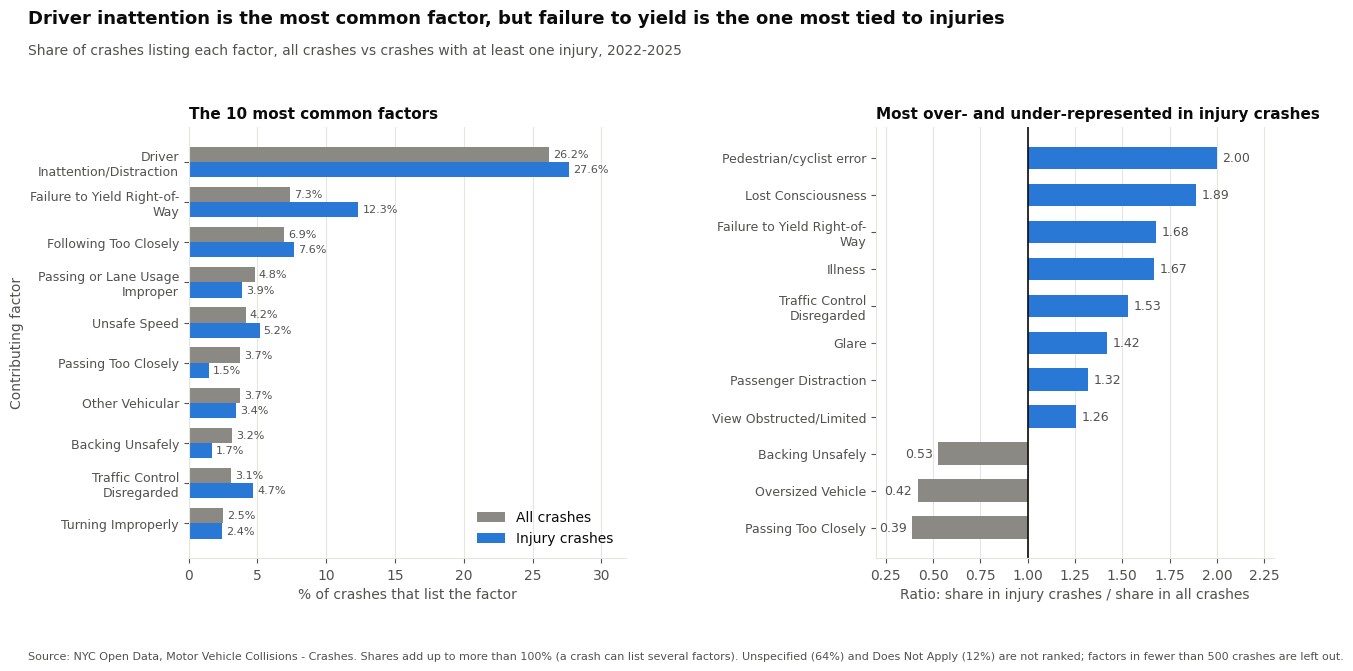

In [18]:
import textwrap
wrap = lambda s: textwrap.fill(s.replace("Pedestrian/Bicyclist/Other Pedestrian Error/Confusion", "Pedestrian/cyclist error"), 26)

top = ranked_f.sort_values("rank_all").head(10)
sel = pd.concat([ranked_f.sort_values("ratio", ascending=False).head(8), ranked_f.sort_values("ratio").head(3)])
sel = sel.sort_values("ratio")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [1.1, 1]})

# left: the 10 most common factors, share in all crashes vs share in injury crashes
y = np.arange(len(top))[::-1]
h = 0.38
a1.barh(y + h / 2, top["share_all"], h, color=GRAY, label="All crashes")
a1.barh(y - h / 2, top["share_injury"], h, color=BLUE, label="Injury crashes")
for yy, v in zip(y + h / 2, top["share_all"]): a1.text(v + 0.3, yy, f"{v:.1f}%", va="center", fontsize=8, color=INK2)
for yy, v in zip(y - h / 2, top["share_injury"]): a1.text(v + 0.3, yy, f"{v:.1f}%", va="center", fontsize=8, color=INK2)
a1.set_yticks(y); a1.set_yticklabels([wrap(f) for f in top.index], fontsize=9)
a1.set_xlim(0, top[["share_all", "share_injury"]].values.max() * 1.15)
a1.set_xlabel("% of crashes that list the factor"); a1.set_ylabel("Contributing factor")
a1.set_title("The 10 most common factors")
a1.legend(loc="lower right"); a1.grid(axis="y", visible=False)

# right: ratio, bars start at 1 (same share in both)
y2 = np.arange(len(sel))
colors = [BLUE if r > 1 else GRAY for r in sel["ratio"]]
a2.barh(y2, sel["ratio"] - 1, left=1, color=colors, height=0.6)
for yy, r in zip(y2, sel["ratio"]):
    a2.text(r + (0.03 if r > 1 else -0.03), yy, f"{r:.2f}", va="center", ha="left" if r > 1 else "right", fontsize=9, color=INK2)
a2.axvline(1, color=INK, linewidth=1.2)
a2.set_yticks(y2); a2.set_yticklabels([wrap(f) for f in sel.index], fontsize=9)
a2.set_xlim(0.2, 2.3)
a2.set_xlabel("Ratio: share in injury crashes / share in all crashes")
a2.set_title("Most over- and under-represented in injury crashes")
a2.grid(axis="y", visible=False)

fig.subplots_adjust(wspace=0.6)
headline(fig, "Driver inattention is the most common factor, but failure to yield is the one most tied to injuries",
         "Share of crashes listing each factor, all crashes vs crashes with at least one injury, 2022-2025")
footer(fig, "Shares add up to more than 100% (a crash can list several factors). Unspecified (64%) and Does Not Apply (12%) are not ranked; factors in fewer than 500 crashes are left out.")
save(fig, "q3_factors")
plt.show()

### What I found: Q3
- Unspecified is in 64.4% of all crashes (53.8% of injury crashes) and Does Not Apply in 12.4%, so most crashes don't have a useful factor. The percentages below are only for the factors that do.
- The most common factor is Driver Inattention/Distraction (26.2% of all crashes), then Failure to Yield Right-of-Way (7.3%) and Following Too Closely (6.9%). These 3 are also the top 3 in injury crashes, so the top of the ranking doesn't change.
- Failure to Yield is much more common in injury crashes: 12.3% vs 7.3%, a ratio of 1.68. Traffic Control Disregarded also goes up (3.1% to 4.7%, ratio 1.53, from rank 9 to rank 5) and Unsafe Speed too (ratio 1.24).
- Driver Inattention is the most common factor, but its ratio is only 1.05, so it is not really more linked to injuries than to other crashes.
- The highest ratios are Pedestrian/cyclist error (2.00) and Lost Consciousness (1.89), but they are small factors (4,973 and 786 crashes).
- On the other side, Passing Too Closely goes down a lot (ratio 0.39, rank 6 to 14) and so does Backing Unsafely (0.53, rank 8 to 13).

**Warning:** a ratio over 1 means the factor shows up more in injury crashes, it doesn't mean it causes the injuries (for example pedestrians get hurt more easily in any crash). Also the factor is what the police wrote down, and more than three quarters of the crashes are Unspecified or Does Not Apply, so the ranking only describes the crashes that have a real factor. Alcohol Involvement has a ratio of 0.89, I wouldn't read that as alcohol being safer, it is more likely a reporting problem.

## Answer to Q3
Driver Inattention/Distraction is the most common contributing factor (26.2% of crashes), followed by Failure to Yield and Following Too Closely, and the top 3 stay the same in injury crashes. Failure to Yield (ratio 1.68) and Traffic Control Disregarded (1.53) are the most over-represented in injury crashes among the common factors, while Driver Inattention is common but not especially linked to injuries (1.05).

---
# Q4. How do injuries and deaths differ among pedestrians, cyclists, motorists and others?

**What I measured:** the number of people injured and killed in each group, and how deadly each group is: deaths per 1,000 injured. I use per 1,000 because the plain ratio gives very small decimals. After that I split it by borough, by time of day and by contributing factor.
**Years I used:** 2022 to 2025 (full years), same as the other questions.

**Decisions**
- "Other" is the group I made in the cleaning notebook: people hurt or killed who are not pedestrians, cyclists or motorists (the gap in the original columns).
- By borough I only show a rate when the group has at least 10 deaths, because with fewer deaths the rate jumps around a lot. Unknown borough is in the tables but not in the chart.
- By hour I use 4 blocks of 6 hours (not 24 hours) because there are too few deaths per hour, and I leave out the crashes at exactly 00:00 like in Q1.
- By factor I use the factors ranked in Q3 and a crash with more than one factor counts in each of them. I only show factors with at least 15 deaths.

In [19]:
# injured and killed for each group (the "other" group was created in the cleaning notebook)
groups = {
    "Pedestrians": ("NUMBER OF PEDESTRIANS INJURED", "NUMBER OF PEDESTRIANS KILLED"),
    "Cyclists": ("NUMBER OF CYCLIST INJURED", "NUMBER OF CYCLIST KILLED"),
    "Motorists": ("NUMBER OF MOTORIST INJURED", "NUMBER OF MOTORIST KILLED"),
    "Other": ("OTHER INJURED", "OTHER KILLED"),
}
GROUP_COLOR = {"Pedestrians": BLUE, "Cyclists": ORANGE, "Motorists": AQUA, "Other": GRAY}

q4_df = df[df["CRASH YEAR"].between(2022, 2025)]
q4 = pd.DataFrame({g: {"injured": q4_df[i].sum(), "killed": q4_df[k].sum()} for g, (i, k) in groups.items()}).T
q4["killed_per_1000_injured"] = q4["killed"] / q4["injured"] * 1000   # severity rate
q4["share_of_injured"] = q4["injured"] / q4["injured"].sum() * 100
q4["share_of_killed"] = q4["killed"] / q4["killed"].sum() * 100

# check: the 4 groups add up to the total columns
assert q4["injured"].sum() == q4_df["NUMBER OF PERSONS INJURED"].sum()
assert q4["killed"].sum() == q4_df["NUMBER OF PERSONS KILLED"].sum()
q4.round(1)

,injured,killed,killed_per_1000_injured,share_of_injured,share_of_killed
Pedestrians,36798,485,13.2,17.5,45.5
Cyclists,19928,82,4.1,9.5,7.7
Motorists,143494,416,2.9,68.4,39.0
Other,9637,84,8.7,4.6,7.9


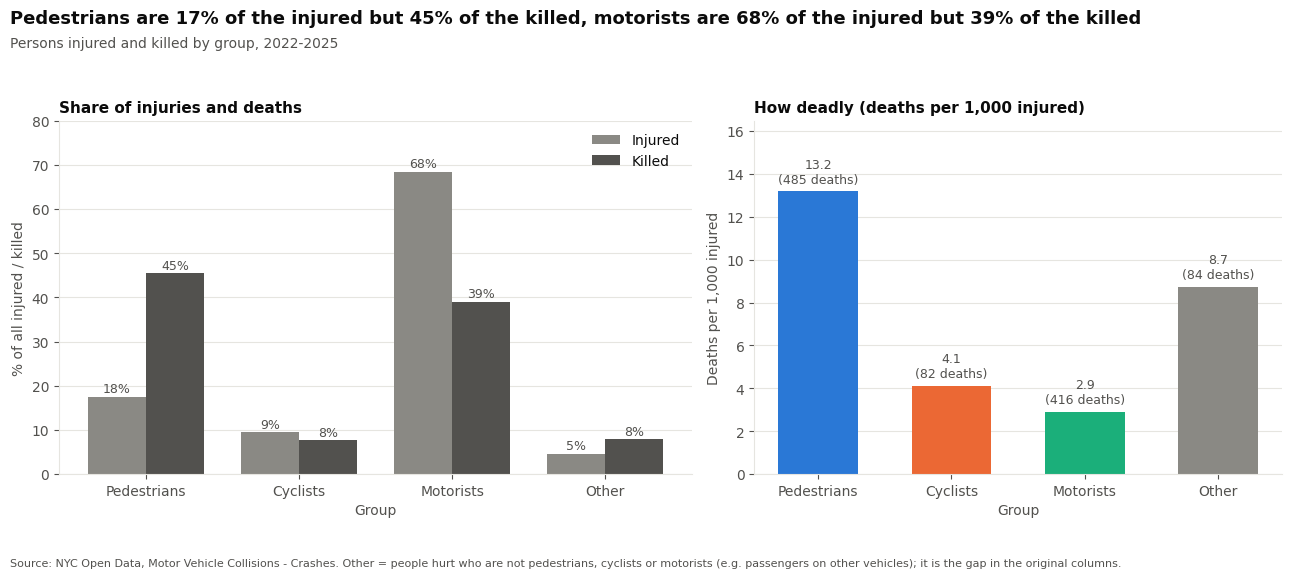

In [20]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})

# left: how much of the injuries and deaths each group has
x = np.arange(len(q4)); w = 0.38
a1.bar(x - w / 2, q4["share_of_injured"], w, color=GRAY, label="Injured")
a1.bar(x + w / 2, q4["share_of_killed"], w, color=INK2, label="Killed")
for xx, v in zip(x - w / 2, q4["share_of_injured"]): a1.text(xx, v + 1, f"{v:.0f}%", ha="center", fontsize=9, color=INK2)
for xx, v in zip(x + w / 2, q4["share_of_killed"]): a1.text(xx, v + 1, f"{v:.0f}%", ha="center", fontsize=9, color=INK2)
a1.set_xticks(x); a1.set_xticklabels(q4.index)
a1.set_ylim(0, 80); a1.set_ylabel("% of all injured / killed"); a1.set_xlabel("Group")
a1.set_title("Share of injuries and deaths"); a1.legend(); a1.grid(axis="x", visible=False)

# right: deaths for every 1,000 injured
bars = a2.bar(q4.index, q4["killed_per_1000_injured"], color=[GROUP_COLOR[g] for g in q4.index], width=0.6)
for b, v, k in zip(bars, q4["killed_per_1000_injured"], q4["killed"]):
    a2.text(b.get_x() + b.get_width() / 2, v + 0.4, f"{v:.1f}\n({k:,.0f} deaths)", ha="center", fontsize=9, color=INK2)
a2.set_ylim(0, q4["killed_per_1000_injured"].max() * 1.25)
a2.set_ylabel("Deaths per 1,000 injured"); a2.set_xlabel("Group")
a2.set_title("How deadly (deaths per 1,000 injured)"); a2.grid(axis="x", visible=False)

headline(fig, "Pedestrians are 17% of the injured but 45% of the killed, motorists are 68% of the injured but 39% of the killed", "Persons injured and killed by group, 2022-2025")
footer(fig, "Other = people hurt who are not pedestrians, cyclists or motorists (e.g. passengers on other vehicles); it is the gap in the original columns.")
fig.tight_layout(); save(fig, "q4_groups"); plt.show()

### What I found: overall
- In 2022-2025 there were 209,857 people injured and 1,067 killed. That is about 5 deaths for every 1,000 injured.
- Motorists are most of the injured (143,494, 68.4%) but they have 416 deaths (39.0%). Pedestrians are 36,798 injured (17.5%) and 485 deaths (45.5%), so pedestrians have more deaths than motorists with 4 times fewer injured.
- Deaths per 1,000 injured: pedestrians 13.2, other 8.7, cyclists 4.1 and motorists 2.9. A hurt pedestrian is about 4.5 times more likely to die than a hurt motorist, and a hurt cyclist about 1.4 times.
- Cyclists are 9.5% of the injured but only 7.7% of the deaths (82).

**Warning:** these are people hurt or killed in a crash that was reported, so the rates don't say how dangerous it is to walk or ride (I don't know how many people walk or ride). Also "other" is a small and mixed group.

In [21]:
# by borough: deaths per 1,000 injured for each group
# the counts of deaths are small, so I only show a rate when there are at least 10 deaths
MIN_DEATHS = 10
borough_inj = pd.DataFrame({g: q4_df.groupby("BOROUGH")[i].sum() for g, (i, k) in groups.items()})
borough_kil = pd.DataFrame({g: q4_df.groupby("BOROUGH")[k].sum() for g, (i, k) in groups.items()})
b_rate = (borough_kil / borough_inj * 1000).where(borough_kil >= MIN_DEATHS)
order_b = NAMED   # unknown is left out of the chart (its share changes a lot over time)

print("Injured:"); display(borough_inj.loc[order_b + ["Unknown"]])
print("Killed:"); display(borough_kil.loc[order_b + ["Unknown"]])
print("Deaths per 1,000 injured (blank = fewer than 10 deaths):"); display(b_rate.loc[order_b + ["Unknown"]].round(1))

Injured:


,Pedestrians,Cyclists,Motorists,Other
BOROUGH,,,,
BRONX,5087,1721,17340,1283
BROOKLYN,10217,5876,33453,3236
MANHATTAN,6211,5321,10938,1341
QUEENS,7714,3067,27678,2035
STATEN ISLAND,918,212,4278,102
Unknown,6651,3731,49807,1640


Killed:


,Pedestrians,Cyclists,Motorists,Other
BOROUGH,,,,
BRONX,53,12,51,14
BROOKLYN,116,23,62,20
MANHATTAN,78,14,23,11
QUEENS,75,12,65,18
STATEN ISLAND,16,1,14,0
Unknown,147,20,201,21


Deaths per 1,000 injured (blank = fewer than 10 deaths):


,Pedestrians,Cyclists,Motorists,Other
BOROUGH,,,,
BRONX,10.4,7.0,2.9,10.9
BROOKLYN,11.4,3.9,1.9,6.2
MANHATTAN,12.6,2.6,2.1,8.2
QUEENS,9.7,3.9,2.3,8.8
STATEN ISLAND,17.4,NaN,3.3,NaN
Unknown,22.1,5.4,4.0,12.8


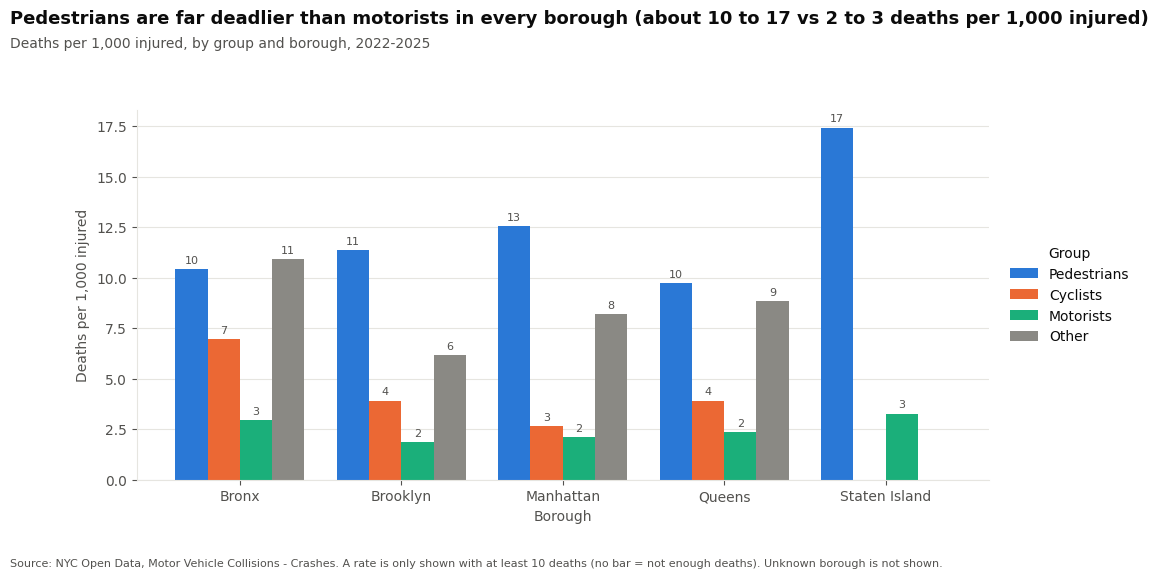

In [22]:
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(order_b)); w = 0.2
for j, g in enumerate(groups):
    vals = b_rate.loc[order_b, g]
    bars = ax.bar(x + (j - 1.5) * w, vals.fillna(0), w, color=GROUP_COLOR[g], label=g)
    for xx, v in zip(x + (j - 1.5) * w, vals):
        if pd.notna(v): ax.text(xx, v + 0.3, f"{v:.0f}", ha="center", fontsize=8, color=INK2)
ax.set_xticks(x); ax.set_xticklabels([label(b) for b in order_b])
ax.set_xlabel("Borough"); ax.set_ylabel("Deaths per 1,000 injured")
ax.legend(title="Group", loc="center left", bbox_to_anchor=(1.01, 0.5)); ax.grid(axis="x", visible=False)
headline(fig, "Pedestrians are far deadlier than motorists in every borough (about 10 to 17 vs 2 to 3 deaths per 1,000 injured)", "Deaths per 1,000 injured, by group and borough, 2022-2025")
footer(fig, "A rate is only shown with at least 10 deaths (no bar = not enough deaths). Unknown borough is not shown.")
save(fig, "q4_borough"); plt.show()

### What I found: borough
- Pedestrians have a death rate far above motorists in every borough: 9.7 (Queens) to 12.6 (Manhattan) per 1,000 injured, and 17.4 in Staten Island, against 1.9 to 3.3 for motorists.
- In counts, Brooklyn has the most pedestrian deaths (116), then Manhattan (78) and Queens (75).
- Cyclists in the Bronx have a higher rate (7.0) than in Manhattan (2.6), Brooklyn or Queens (3.9), but each of those is based on only 12 to 23 deaths.
- In the Bronx the "other" group (10.9) is slightly above pedestrians (10.4).

**Warning:** more than a third of the deaths (36%) are in Unknown borough, so the borough numbers leave out a lot, and Staten Island has very few deaths (16 pedestrians), so its rate of 17.4 is not very reliable. I would not say that one borough is more dangerous than another from this.

In [23]:
# by hour: I group the hours in 4 blocks, with 1 hour the deaths are too few
hourly4 = q4_df[q4_df["CRASH TIME"] != "00:00"].copy()   # 00:00 is left out like in Q1
hourly4["BLOCK"] = pd.cut(hourly4["CRASH HOUR"], [-1, 5, 11, 17, 23],
                          labels=["12 am - 5 am", "6 am - 11 am", "12 pm - 5 pm", "6 pm - 11 pm"])
h_inj = pd.DataFrame({g: hourly4.groupby("BLOCK", observed=True)[i].sum() for g, (i, k) in groups.items()})
h_kil = pd.DataFrame({g: hourly4.groupby("BLOCK", observed=True)[k].sum() for g, (i, k) in groups.items()})
h_rate = h_kil / h_inj * 1000
print("Injured:"); display(h_inj)
print("Killed:"); display(h_kil)
print("Deaths per 1,000 injured:"); display(h_rate.round(1))
print("Share of all deaths in each block (%):"); display((h_kil.sum(axis=1) / h_kil.sum().sum() * 100).round(1).to_frame("share_of_deaths").T)

Injured:


,Pedestrians,Cyclists,Motorists,Other
BLOCK,,,,
12 am - 5 am,2274,1341,21057,764
6 am - 11 am,8880,4149,32357,1972
12 pm - 5 pm,13796,7775,47019,3657
6 pm - 11 pm,11282,6333,40669,3030


Killed:


,Pedestrians,Cyclists,Motorists,Other
BLOCK,,,,
12 am - 5 am,108,13,165,18
6 am - 11 am,99,25,57,20
12 pm - 5 pm,102,20,75,24
6 pm - 11 pm,176,24,119,22


Deaths per 1,000 injured:


,Pedestrians,Cyclists,Motorists,Other
BLOCK,,,,
12 am - 5 am,47.5,9.7,7.8,23.6
6 am - 11 am,11.1,6.0,1.8,10.1
12 pm - 5 pm,7.4,2.6,1.6,6.6
6 pm - 11 pm,15.6,3.8,2.9,7.3


Share of all deaths in each block (%):


BLOCK,12 am - 5 am,6 am - 11 am,12 pm - 5 pm,6 pm - 11 pm
share_of_deaths,28.5,18.8,20.7,32.0


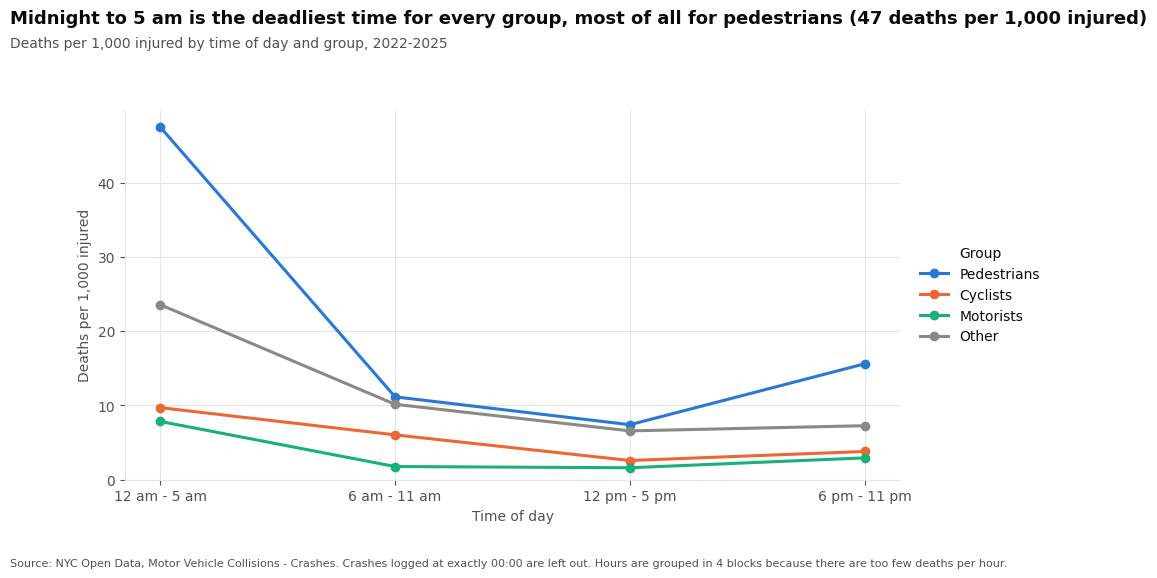

In [24]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for g in groups:
    ax.plot(h_rate.index.astype(str), h_rate[g], marker="o", linewidth=2.2, color=GROUP_COLOR[g], label=g)
ax.set_xlabel("Time of day"); ax.set_ylabel("Deaths per 1,000 injured"); ax.set_ylim(0, None)
ax.legend(title="Group", loc="center left", bbox_to_anchor=(1.01, 0.5))
headline(fig, "Midnight to 5 am is the deadliest time for every group, most of all for pedestrians (47 deaths per 1,000 injured)", "Deaths per 1,000 injured by time of day and group, 2022-2025")
footer(fig, "Crashes logged at exactly 00:00 are left out. Hours are grouped in 4 blocks because there are too few deaths per hour.")
save(fig, "q4_hour"); plt.show()

### What I found: time of day
- From midnight to 5 am the death rate is the highest for every group: pedestrians 47.5, other 23.6, cyclists 9.7 and motorists 7.8 deaths per 1,000 injured.
- That block has 12.3% of the injured but 28.5% of the deaths. In the afternoon (12 pm to 5 pm) it is the lowest for every group (pedestrians 7.4, motorists 1.6).
- The block with the most deaths is 6 pm to 11 pm (32.0% of all deaths). 176 pedestrians died then, 36% of all the pedestrian deaths.
- So the early morning is the deadliest per injury and the evening has the most deaths in total, because there are many more crashes.

**Warning:** the groups are 6-hour blocks and cyclists and other have few deaths in each block (13 to 25), so only the big differences are worth reading. It also only has crashes with a time (00:00 is left out).

In [25]:
# by contributing factor: I use the factors ranked in Q3 (without Unspecified / Does Not Apply, 500 crashes or more)
# a crash with 2 factors counts in both, and all its injured and killed are given to each factor
outcome_cols = ["COLLISION_ID", "NUMBER OF PERSONS INJURED", "NUMBER OF PERSONS KILLED"] + [c for pair in groups.values() for c in pair]
fx = long[["COLLISION_ID", "FACTOR"]].merge(q4_df[outcome_cols], on="COLLISION_ID")
fx = fx[fx["FACTOR"].isin(ranked_f.index)]

by_factor = fx.groupby("FACTOR").agg(
    crashes=("COLLISION_ID", "nunique"),
    injured=("NUMBER OF PERSONS INJURED", "sum"),
    killed=("NUMBER OF PERSONS KILLED", "sum"),
    ped_killed=("NUMBER OF PEDESTRIANS KILLED", "sum"),
    motorist_killed=("NUMBER OF MOTORIST KILLED", "sum"),
)
by_factor["killed_per_1000_injured"] = by_factor["killed"] / by_factor["injured"] * 1000
by_factor["pedestrian_share_of_deaths"] = by_factor["ped_killed"] / by_factor["killed"] * 100
shown = by_factor[by_factor["killed"] >= 15].sort_values("killed_per_1000_injured", ascending=False)   # at least 15 deaths
print("Factors with at least 15 deaths:", len(shown), "of", len(by_factor))
shown.round(1)

Factors with at least 15 deaths: 9 of 29


,crashes,injured,killed,ped_killed,motorist_killed,killed_per_1000_injured,pedestrian_share_of_deaths
FACTOR,,,,,,,
Lost Consciousness,786,861,25,2,21,29.0,8.0
Unsafe Speed,15671,12782,188,38,140,14.7,20.2
Alcohol Involvement,7271,4153,40,12,25,9.6,30.0
Traffic Control Disregarded,11586,10730,96,23,44,8.9,24.0
Pedestrian/Bicyclist/Other Pedestrian Error/Confusion,4973,4387,28,16,1,6.4,57.1
Driver Inexperience,8888,4887,30,2,18,6.1,6.7
Failure to Yield Right-of-Way,27717,23800,99,68,16,4.2,68.7
Passing or Lane Usage Improper,18100,8109,29,1,19,3.6,3.4
Driver Inattention/Distraction,98848,56896,147,83,38,2.6,56.5


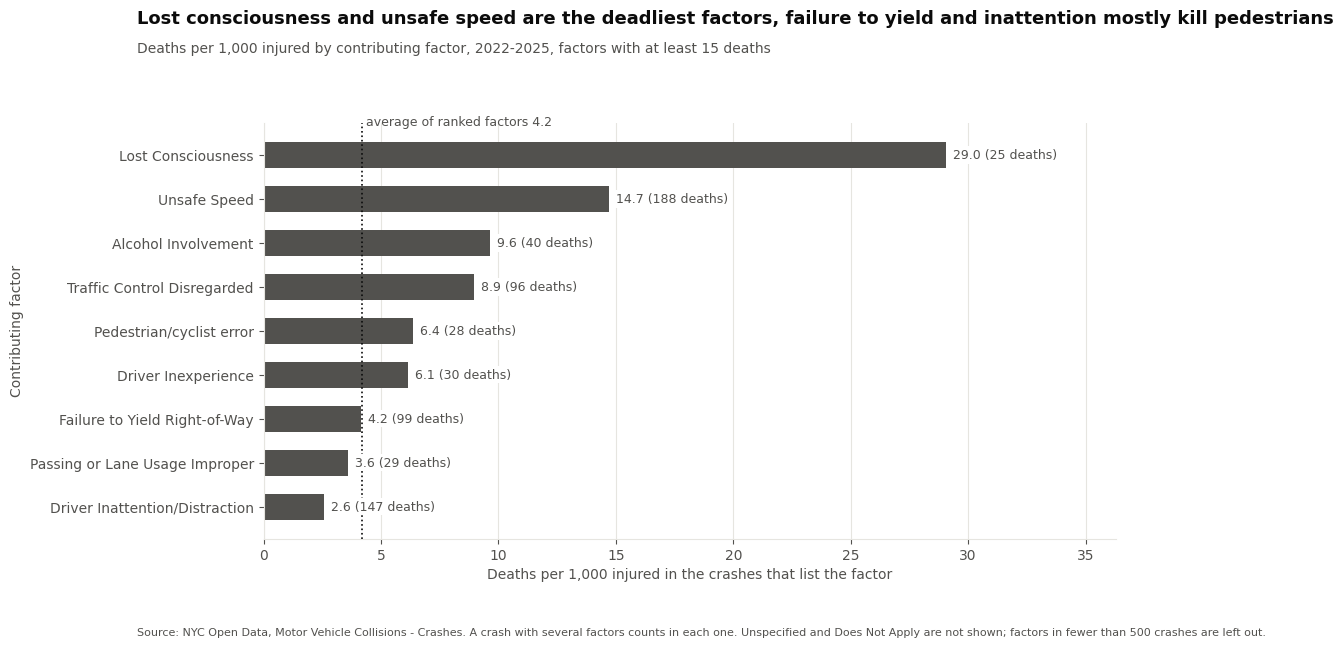

In [26]:
plot_f = shown.head(12).sort_values("killed_per_1000_injured")
fig, ax = plt.subplots(figsize=(11, 5.4))
import textwrap
names = [textwrap.fill(n.replace("Pedestrian/Bicyclist/Other Pedestrian Error/Confusion", "Pedestrian/cyclist error"), 30) for n in plot_f.index]
bars = ax.barh(names, plot_f["killed_per_1000_injured"], color=INK2, height=0.6)
avg_rate = by_factor["killed"].sum() / by_factor["injured"].sum() * 1000
ax.axvline(avg_rate, color=INK, linestyle=":", linewidth=1.2)
ax.text(avg_rate, len(plot_f) - 0.4, f" average of ranked factors {avg_rate:.1f}", fontsize=9, color=INK2, va="bottom")
for b, v, k in zip(bars, plot_f["killed_per_1000_injured"], plot_f["killed"]):
    ax.text(v + 0.3, b.get_y() + b.get_height() / 2, f"{v:.1f} ({k:.0f} deaths)", va="center", fontsize=9, color=INK2,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5), zorder=3)
ax.set_xlim(0, plot_f["killed_per_1000_injured"].max() * 1.25)
ax.set_xlabel("Deaths per 1,000 injured in the crashes that list the factor"); ax.set_ylabel("Contributing factor")
ax.grid(axis="y", visible=False)
headline(fig, "Lost consciousness and unsafe speed are the deadliest factors, failure to yield and inattention mostly kill pedestrians", "Deaths per 1,000 injured by contributing factor, 2022-2025, factors with at least 15 deaths")
footer(fig, "A crash with several factors counts in each one. Unspecified and Does Not Apply are not shown; factors in fewer than 500 crashes are left out.")
save(fig, "q4_factor"); plt.show()

### What I found: contributing factor
- Only 9 of the 29 ranked factors have at least 15 deaths.
- Deaths per 1,000 injured: Lost Consciousness 29.0 (25 deaths), Unsafe Speed 14.7 (188 deaths), Alcohol Involvement 9.6 (40), Traffic Control Disregarded 8.9 (96), Pedestrian/cyclist error 6.4 (28), Driver Inexperience 6.1 (30), Failure to Yield 4.2 (99), Passing or Lane Usage Improper 3.6 (29) and Driver Inattention 2.6 (147).
- Unsafe Speed has the most deaths of all these factors (188) and 74% of them are motorists (140).
- Failure to Yield and Driver Inattention are not very deadly per injury, but a lot of their deaths are pedestrians (69% and 57%). Driver Inattention is the most common factor in Q3 and has the lowest death rate here.

**Warning:** a crash with several factors counts in each one, so I can't say which factor caused the deaths. Lost Consciousness has a very high rate but only 25 deaths and 861 injured. Most crashes are Unspecified or Does Not Apply and they are not in this part, so it only describes the crashes with a real factor.

## Answer to Q4
Pedestrians are the group that suffers the most: they are 17.5% of the injured but 45.5% of the deaths, with 13.2 deaths per 1,000 injured against 2.9 for motorists and 4.1 for cyclists. This is true in every borough and it is worst from midnight to 5 am (47.5 deaths per 1,000 injured pedestrians). By factor, Unsafe Speed has the most deaths (mostly motorists), while Failure to Yield and Driver Inattention kill mostly pedestrians.

---
# Q5. Which vehicle types appear most often in crashes in each borough?

**What I measured:** the number of crashes that involve each vehicle type, in each borough, and the share of that borough's crashes (crashes with the type / all crashes of the borough). Then I rank the types inside each borough.
**Years I used:** 2022 to 2025 (full years), same as the other questions.

**Decisions**
- A crash counts once for a vehicle type, even if 2 vehicles of that type are in it (for example 2 cars). The vehicle types come from the groups I made in the cleaning notebook (`VEHICLE CAT 1` to `5`).
- "unknown" and "other" are not real types, so they are in the table but I don't rank them.
- Because a crash can have several types, the shares add up to more than 100%.
- Unknown borough is in the table but not in the chart.

In [27]:
# one row per crash and vehicle type (a crash counts once per type)
vcat_cols = [f"VEHICLE CAT {i}" for i in range(1, 6)]
q5_df = df[df["CRASH YEAR"].between(2022, 2025)]

v_long = (
    q5_df[["COLLISION_ID", "BOROUGH"] + vcat_cols]
    .melt(id_vars=["COLLISION_ID", "BOROUGH"], value_vars=vcat_cols, value_name="TYPE")
    .dropna(subset=["TYPE"])
    .drop(columns="variable")
    .drop_duplicates(subset=["COLLISION_ID", "TYPE"])
)
print("Crashes with at least one vehicle type:", v_long["COLLISION_ID"].nunique(), "of", len(q5_df))

cols_b = NAMED + ["Unknown"]
v_counts = v_long.groupby(["TYPE", "BOROUGH"]).size().unstack()[cols_b]
crashes_b = q5_df.groupby("BOROUGH").size()[cols_b]
v_share = v_counts / crashes_b * 100
v_share = v_share.loc[v_counts.sum(axis=1).sort_values(ascending=False).index]   # most common first

print("Crashes of each borough:"); display(crashes_b.to_frame("crashes").T)
print("Crashes involving each vehicle type:"); display(v_counts.loc[v_share.index])
print("Share of the borough's crashes (%):"); display(v_share.round(1))

Crashes with at least one vehicle type: 371289 of 377371
Crashes of each borough:


BOROUGH,BRONX,BROOKLYN,MANHATTAN,QUEENS,STATEN ISLAND,Unknown
crashes,45127,95766,50217,75877,11268,99116


Crashes involving each vehicle type:


BOROUGH,BRONX,BROOKLYN,MANHATTAN,QUEENS,STATEN ISLAND,Unknown
TYPE,,,,,,
car / SUV,39942,86137,40106,69924,10570,90443
truck,3552,7796,4939,4172,371,9650
bicycle,1708,6045,6662,3138,228,3947
pickup,1959,4178,2069,3774,869,5293
motorcycle / moped,2345,4382,1993,3390,225,3461
taxi / limo,1627,2279,5644,1745,81,3893
e-bike / e-scooter,1766,4464,2562,2717,122,2724
bus,1980,3673,2629,1996,435,3208
van,615,1297,971,581,62,1167


Share of the borough's crashes (%):


BOROUGH,BRONX,BROOKLYN,MANHATTAN,QUEENS,STATEN ISLAND,Unknown
TYPE,,,,,,
car / SUV,88.5,89.9,79.9,92.2,93.8,91.2
truck,7.9,8.1,9.8,5.5,3.3,9.7
bicycle,3.8,6.3,13.3,4.1,2.0,4.0
pickup,4.3,4.4,4.1,5.0,7.7,5.3
motorcycle / moped,5.2,4.6,4.0,4.5,2.0,3.5
taxi / limo,3.6,2.4,11.2,2.3,0.7,3.9
e-bike / e-scooter,3.9,4.7,5.1,3.6,1.1,2.7
bus,4.4,3.8,5.2,2.6,3.9,3.2
van,1.4,1.4,1.9,0.8,0.6,1.2


In [28]:
# ranking inside each borough (without unknown and other)
real = v_counts.drop(index=["unknown", "other"])
v_rank = real.rank(ascending=False, method="min").astype(int)
v_rank = v_rank.loc[real.sum(axis=1).sort_values(ascending=False).index]
print("Rank of each vehicle type in each borough (1 = most crashes):")
display(v_rank)
print("Top 3 in each borough:")
for b in NAMED:
    print(f"  {label(b)}:", ", ".join(f"{t} ({v_share.loc[t, b]:.1f}%)" for t in real[b].sort_values(ascending=False).index[:3]))

Rank of each vehicle type in each borough (1 = most crashes):


BOROUGH,BRONX,BROOKLYN,MANHATTAN,QUEENS,STATEN ISLAND,Unknown
TYPE,,,,,,
car / SUV,1,1,1,1,1,1
truck,2,2,4,2,4,2
bicycle,7,3,2,5,5,4
pickup,5,6,7,3,2,3
motorcycle / moped,3,5,8,4,6,6
taxi / limo,8,8,3,8,9,5
e-bike / e-scooter,6,4,6,6,7,8
bus,4,7,5,7,3,7
van,10,9,9,10,10,9


Top 3 in each borough:
  Bronx: car / SUV (88.5%), truck (7.9%), motorcycle / moped (5.2%)
  Brooklyn: car / SUV (89.9%), truck (8.1%), bicycle (6.3%)
  Manhattan: car / SUV (79.9%), bicycle (13.3%), taxi / limo (11.2%)
  Queens: car / SUV (92.2%), truck (5.5%), pickup (5.0%)
  Staten Island: car / SUV (93.8%), pickup (7.7%), bus (3.9%)


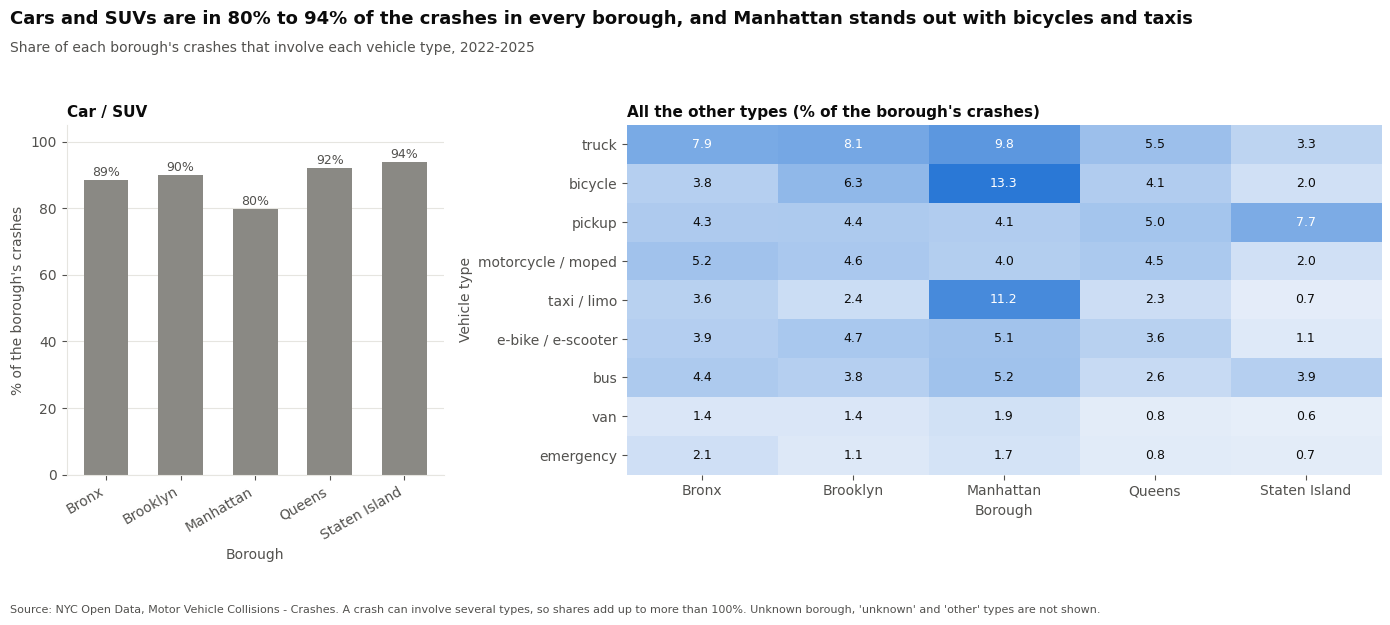

In [29]:
from matplotlib.colors import LinearSegmentedColormap
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [0.8, 1.6]})

# left: car / SUV is in most crashes everywhere
car = v_share.loc["car / SUV", NAMED]
bars = a1.bar([label(b) for b in NAMED], car, color=GRAY, width=0.6)
for b_, v in zip(bars, car): a1.text(b_.get_x() + b_.get_width() / 2, v + 1.2, f"{v:.0f}%", ha="center", fontsize=9, color=INK2)
a1.set_ylim(0, 105); a1.set_ylabel("% of the borough's crashes"); a1.set_xlabel("Borough")
a1.set_title("Car / SUV"); a1.grid(axis="x", visible=False)
plt.setp(a1.get_xticklabels(), rotation=30, ha="right")

# right: all the other types
others = v_share.drop(index=["car / SUV", "unknown", "other"])[NAMED]
cmap = LinearSegmentedColormap.from_list("blues", ["#eef3fb", BLUE])
im = a2.imshow(others.values, cmap=cmap, aspect="auto", vmin=0, vmax=others.values.max())
a2.set_xticks(range(len(NAMED))); a2.set_xticklabels([label(b) for b in NAMED])
a2.set_yticks(range(len(others))); a2.set_yticklabels(others.index)
for i in range(others.shape[0]):
    for j in range(others.shape[1]):
        v = others.values[i, j]
        a2.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=9, color="white" if v > others.values.max() * 0.55 else INK)
a2.grid(False); a2.set_xlabel("Borough"); a2.set_ylabel("Vehicle type")
a2.set_title("All the other types (% of the borough's crashes)")
for s in a2.spines.values(): s.set_visible(False)

headline(fig, "Cars and SUVs are in 80% to 94% of the crashes in every borough, and Manhattan stands out with bicycles and taxis",
         "Share of each borough's crashes that involve each vehicle type, 2022-2025")
footer(fig, "A crash can involve several types, so shares add up to more than 100%. Unknown borough, 'unknown' and 'other' types are not shown.")
fig.tight_layout(); save(fig, "q5_vehicles"); plt.show()

### What I found: Q5
- Car / SUV is the most common type in every borough, in 80% (Manhattan) to 94% (Staten Island) of the crashes. This group joins sedans, SUVs and station wagons, so it doesn't say much about the type.
- Truck is the second most common type in the Bronx (7.9%), Brooklyn (8.1%) and Queens (5.5%). In Staten Island it is pickup (7.7%).
- Manhattan is different: bicycle is second (13.3% of its crashes) and taxi / limo is third (11.2%), then truck (9.8%). In the other boroughs taxi / limo is only 0.7% to 3.6%.
- Bicycles are also high in Brooklyn (6.3%) compared with the Bronx (3.8%) and Queens (4.1%).
- Motorcycle / moped is in 5.2% of the Bronx crashes, the highest of the boroughs. Staten Island has the lowest share of bicycles (2.0%) and e-bikes (1.1%).

**Warning:** this counts crashes that involve a type, it doesn't say which type is more dangerous or has more crashes for each vehicle on the road. A borough with many taxis or bikes will have them in more crashes just because there are more of them. Also the types are groups I made with rules (about 0.4% of the vehicle entries end in "other"), so a few labels could be in the wrong group.

## Answer to Q5
Cars and SUVs appear most often in every borough (80% to 94% of the crashes). After that, trucks are second in the Bronx, Brooklyn and Queens, pickups are second in Staten Island, and Manhattan is the only borough where bicycles (13.3%) and taxis (11.2%) are in the top 3.

---
# Q6. How has the average number of injuries per crash changed from year to year?

**What I measured:** total persons injured / total crashes for each year, and the % change from the previous year.
**Years I used:** 2022 to 2025. 2026 is not a full year (the data ends on Nov 9), so it is only used as a side note.

**Decisions**
- I use all the crashes of each year, including the ones with 0 injuries (same denominator as Q2).
- I also split the change in two parts to understand it: how many crashes have at least one injury, and how many people are hurt in each of those.

In [30]:
q6_df = df[df["CRASH YEAR"].between(2022, 2025)]
q6 = q6_df.groupby("CRASH YEAR").agg(
    crashes=("COLLISION_ID", "size"),
    injured=("NUMBER OF PERSONS INJURED", "sum"),
    injury_crashes=("INJURY CRASH", "sum"),
)
q6["avg_injured"] = q6["injured"] / q6["crashes"]
q6["yoy_change_%"] = q6["avg_injured"].pct_change() * 100          # change from the year before
print(f"Change 2022 -> 2025: {(q6.loc[2025, 'avg_injured'] / q6.loc[2022, 'avg_injured'] - 1) * 100:.1f}%")

# check: the sum of the years is the same as the total of those years
assert q6["crashes"].sum() == len(q6_df)
assert q6["injured"].sum() == q6_df["NUMBER OF PERSONS INJURED"].sum()
q6.round(3)

Change 2022 -> 2025: 16.1%


,crashes,injured,injury_crashes,avg_injured,yoy_change_%
CRASH YEAR,,,,,
2022,103888,51933,39133,0.500,NaN
2023,96608,54253,40265,0.562,12.340
2024,91316,54030,40040,0.592,5.360
2025,85559,49641,37254,0.580,-1.941


In [31]:
# why did it change? crashes with injuries vs crashes without injuries
q6["no_injury_crashes"] = q6["crashes"] - q6["injury_crashes"]
q6["share_injury_crashes_%"] = q6["injury_crashes"] / q6["crashes"] * 100
q6["injured_per_injury_crash"] = q6["injured"] / q6["injury_crashes"]
index_2022 = q6[["no_injury_crashes", "injury_crashes", "injured"]] / q6.loc[2022, ["no_injury_crashes", "injury_crashes", "injured"]] * 100
display(q6[["crashes", "injury_crashes", "no_injury_crashes", "share_injury_crashes_%", "injured_per_injury_crash"]].round(2))
print("Index (2022 = 100):"); display(index_2022.round(1))

# same calculation without unknown borough (its share changed a lot, see Q1)
named = q6_df[q6_df["BOROUGH"] != "Unknown"].groupby("CRASH YEAR")["NUMBER OF PERSONS INJURED"].mean()
print("Average injuries per crash, five named boroughs only:"); display(named.round(3).to_frame("avg_injured").T)

# side note: 2026 vs the same days (Jan 1 to Nov 9) of the other years
same_days = df[df["CRASH INFO"].dt.strftime("%m-%d") < "11-10"].groupby("CRASH YEAR")["NUMBER OF PERSONS INJURED"].mean()
print("Average injuries per crash from Jan 1 to Nov 9 of each year:"); display(same_days.round(3).to_frame("avg_injured").T)

,crashes,injury_crashes,no_injury_crashes,share_injury_crashes_%,injured_per_injury_crash
CRASH YEAR,,,,,
2022,103888,39133,64755,37.67,1.33
2023,96608,40265,56343,41.68,1.35
2024,91316,40040,51276,43.85,1.35
2025,85559,37254,48305,43.54,1.33


Index (2022 = 100):


,no_injury_crashes,injury_crashes,injured
CRASH YEAR,,,
2022,100.0,100.0,100.0
2023,87.0,102.9,104.5
2024,79.2,102.3,104.0
2025,74.6,95.2,95.6


Average injuries per crash, five named boroughs only:


CRASH YEAR,2022,2023,2024,2025
avg_injured,0.468,0.528,0.555,0.572


Average injuries per crash from Jan 1 to Nov 9 of each year:


CRASH YEAR,2022,2023,2024,2025,2026
avg_injured,0.499,0.561,0.594,0.585,0.6


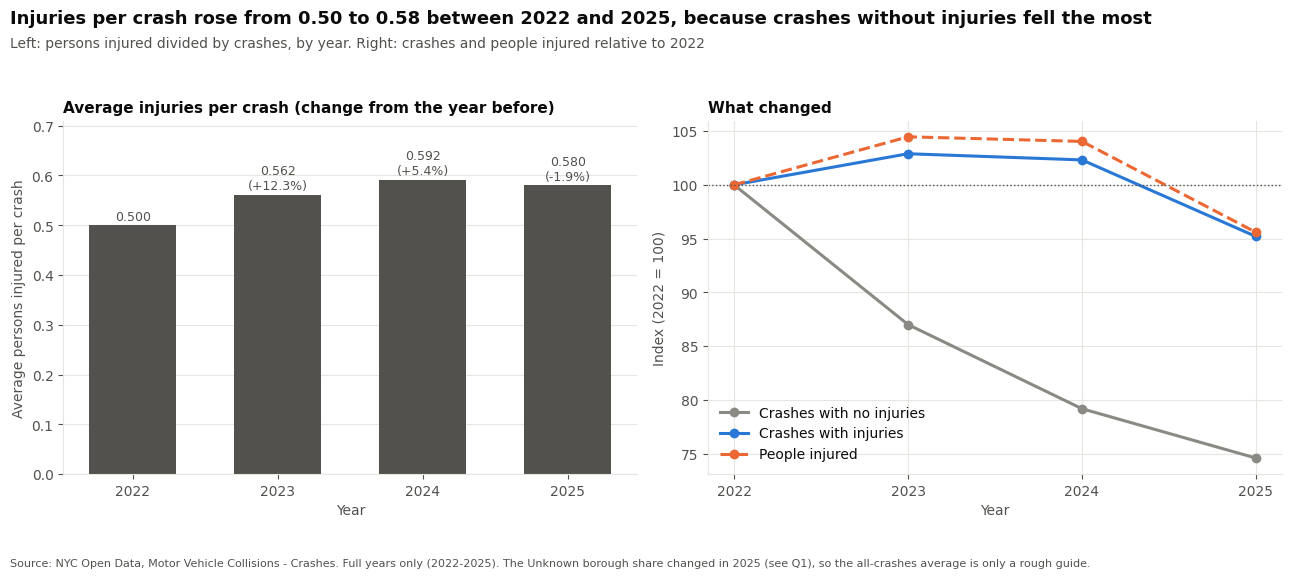

In [32]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))

# left: the average per year
bars = a1.bar(q6.index.astype(str), q6["avg_injured"], color=INK2, width=0.6)
for b_, v, c_ in zip(bars, q6["avg_injured"], q6["yoy_change_%"]):
    txt = f"{v:.3f}" if pd.isna(c_) else f"{v:.3f}\n({c_:+.1f}%)"
    a1.text(b_.get_x() + b_.get_width() / 2, v + 0.01, txt, ha="center", fontsize=9, color=INK2)
a1.set_ylim(0, q6["avg_injured"].max() * 1.2)
a1.set_xlabel("Year"); a1.set_ylabel("Average persons injured per crash")
a1.set_title("Average injuries per crash (change from the year before)"); a1.grid(axis="x", visible=False)

# right: what moved (2022 = 100)
for col, name, color, ls in [("no_injury_crashes", "Crashes with no injuries", GRAY, "-"),
                             ("injury_crashes", "Crashes with injuries", BLUE, "-"),
                             ("injured", "People injured", ORANGE, "--")]:
    a2.plot(index_2022.index, index_2022[col], marker="o", linewidth=2.2, color=color, linestyle=ls, label=name)
a2.axhline(100, color=INK2, linestyle=":", linewidth=1)
a2.set_xticks(index_2022.index); a2.set_xlabel("Year"); a2.set_ylabel("Index (2022 = 100)")
a2.set_title("What changed"); a2.legend(loc="lower left")

headline(fig, "Injuries per crash rose from 0.50 to 0.58 between 2022 and 2025, because crashes without injuries fell the most",
         "Left: persons injured divided by crashes, by year. Right: crashes and people injured relative to 2022")
footer(fig, "Full years only (2022-2025). The Unknown borough share changed in 2025 (see Q1), so the all-crashes average is only a rough guide.")
fig.tight_layout(); save(fig, "q6_year"); plt.show()

### What I found: Q6
- The average number of injuries per crash was 0.500 in 2022, 0.562 in 2023, 0.592 in 2024 and 0.580 in 2025. The change from the year before was +12.3%, +5.4% and -1.9%, and about +16% from 2022 to 2025.
- The reason is that crashes without injuries dropped a lot (64,755 in 2022 to 48,305 in 2025, -25.4%), but crashes with injuries only dropped 4.8% (39,133 to 37,254) and the people injured 4.4% (51,933 to 49,641).
- So the share of crashes that have at least one injury went from 37.7% to 43.5%. The number of people hurt in each injury crash stayed almost the same (1.33 in 2022, 1.35 in 2023 and 2024, 1.33 in 2025).
- With only the five named boroughs the average goes up every year (0.468, 0.528, 0.555, 0.572). The all-crashes number goes down a little in 2025 because the Unknown borough, which has the highest average (0.624 in Q2), is a much smaller share that year.
- Side note: in 2026 (Jan 1 to Nov 9) the average is 0.600, against 0.585 for the same days of 2025.

**Warning:** this doesn't mean that crashes are more violent. The data only has crashes that were reported, and the fall of crashes without injuries may be because fewer minor crashes are reported or recorded, I can't tell that from this data. It also doesn't mean there are more injuries: the total of people injured went down in 2024 and 2025.

## Answer to Q6
The average number of injuries per crash went up from 0.500 in 2022 to 0.580 in 2025 (+12.3% in 2023, +5.4% in 2024 and -1.9% in 2025). It rose because crashes without injuries fell by 25% while crashes with injuries fell only 5%, not because more people were hurt in each crash.